# Введение в анализ данных и машинное обучение

## 0. Установка и импорт пакетов

In [1]:
# %pip install -q numpy pandas matplotlib jinja2 scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import io, urllib.request

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 130)
pd.set_option("display.precision", 3)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

RANDOM_STATE = 42

## 1. Постановка задачи

### 1.1 Обучение с учителем

Пусть задана выборка наблюдений

$$X = \{(\mathbf{x}_i,\, y_i)\}_{i=1}^{n}, \qquad \mathbf{x}_i \in \mathbb{R}^{p},\; y_i \in \mathbb{Y}.$$

Здесь $\mathbf{x}_i$ — вектор признаков $i$-го объекта, $y_i$ — значение целевой переменной,
$n$ — число наблюдений, $p$ — число признаков.
Предполагается, что пары $(\mathbf{x}_i, y_i)$ независимо порождены некоторым
неизвестным совместным распределением $p(\mathbf{x}, y)$.

Тип задачи определяется множеством $\mathbb{Y}$:

* $\mathbb{Y} \subseteq \mathbb{R}$ — **задача регрессии**;
* $\mathbb{Y} = \{c_1, \dots, c_K\}$, конечное неупорядоченное множество — **задача классификации**.

### 1.2 Функция потерь и риск

Качество модели $f$ задаётся **функцией потерь** $L(y, \hat{y})$, штрафующей отклонение
предсказания $\hat{y} = f(\mathbf{x})$ от истинного значения $y$. Идеальная цель — минимизация
**теоретического риска**

$$R(f) = \mathbb{E}_{(\mathbf{x}, y) \sim p}\, L\big(y,\, f(\mathbf{x})\big).$$

Распределение $p$ неизвестно: в нашем распоряжении не оно, а конечная выборка из него.
Поэтому вместо $R(f)$ минимизируют его выборочную оценку — **эмпирический риск**:

$$\hat{R}(f) = \frac{1}{n}\sum_{i=1}^{n} L\big(y_i,\, f(\mathbf{x}_i)\big) \;\longrightarrow\; \min_{f \in \mathcal{F}},$$

где $\mathcal{F}$ — заранее выбранный класс функций (например, все линейные функции).

## 2. Загрузка данных

Разделитель полей в этом файле — точка с запятой, что требует явного указания `sep=";"`.

In [3]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-{color}.csv"

def load_wine(color="red") -> pd.DataFrame:
    url = URL.format(color=color)
    try:
        df = pd.read_csv(url, sep=";")
        return df
    except Exception as e:

        print(f"Источник недоступен ({type(e).__name__}): {url}")

df = load_wine()
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5


### Признаки и целевая переменная датасета

| Признак | Смысл |
|---|---|
| `fixed acidity` | нелетучие кислоты|
| `volatile acidity` | летучие кислоты (уксусная)|
| `citric acid` | лимонная кислота|
| `residual sugar` | остаточный сахар|
| `chlorides` | хлориды|
| `free sulfur dioxide` | свободный SO₂|
| `total sulfur dioxide` | общий SO₂|
| `density` | плотность|
| `pH` | водородный показатель |
| `sulphates` | сульфаты|
| `alcohol` | содержание спирта |
| `quality` | целевая переменная: медиана оценок трёх экспертов, шкала 0–10 |

## 3. Вспоминаем pandas: структура данных, индексация и отбор

### 3.1 Объекты pandas

Библиотека оперирует двумя структурами:

* `Series` — одномерный массив значений с индексом; соответствует одному столбцу;
* `DataFrame` — двумерная таблица, набор `Series` с общим индексом.

В терминах раздела 1: строка таблицы — объект $\mathbf{x}_i$, столбец — признак,
выделенный столбец `quality` — целевая переменная $y$.

In [4]:
print("Тип объекта:      ", type(df).__name__)
print("Форма (n, p+1):   ", df.shape)
print("Тип столбца:      ", type(df["alcohol"]).__name__)
print("Индекс:           ", df.index)
print("Имена столбцов:   ", list(df.columns))

Тип объекта:       DataFrame
Форма (n, p+1):    (1599, 12)
Тип столбца:       Series
Индекс:            RangeIndex(start=0, stop=1599, step=1)
Имена столбцов:    ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [5]:
df.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

### 3.2 Проверка целостности данных

Три проверки, предшествующие любому анализу: пропуски, дубликаты, диапазоны значений.

Пропущенные значения по столбцам.

In [6]:
missing = df.isna().sum()
missing

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [7]:
n_dup = df.duplicated().sum()
print(f"Полных дубликатов строк: {n_dup} ({n_dup / len(df):.1%} выборки)")

Полных дубликатов строк: 240 (15.0% выборки)


Наличие 240 идентичных строк — важно это запомнить.

Дубликаты здесь, вероятно, не ошибка: разные бутылки одной партии дают
одинаковые результаты анализа и одинаковую оценку. Но на этапах обучения и проверки качества модели
они могут создадавать проблемы.

Посмотрим на базовые статистики колонок нашего датасета.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


### 3.3 Индексация и отбор

Три основных способа обращения к данным:

* `df[...]` — отбор столбцов или булева маска по строкам;
* `df.loc[строки, столбцы]` — отбор по меткам;
* `df.iloc[строки, столбцы]` — отбор по позициям.

In [9]:
df.head(100)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
95,4.7,0.600,0.17,2.3,0.058,17.0,106.0,0.993,3.85,0.60,12.9,6
96,6.8,0.775,0.00,3.0,0.102,8.0,23.0,0.997,3.45,0.56,10.7,5
97,7.0,0.500,0.25,2.0,0.070,3.0,22.0,0.996,3.25,0.63,9.2,5
98,7.6,0.900,0.06,2.5,0.079,5.0,10.0,0.997,3.39,0.56,9.8,5


In [10]:
print(df["alcohol"].head(3), "\n")
print(df[["alcohol", "quality"]].head(3))

0    9.4
1    9.8
2    9.8
Name: alcohol, dtype: float64 

   alcohol  quality
0      9.4        5
1      9.8        5
2      9.8        5


In [11]:
print(df.loc[0:2, "alcohol":"quality"], "\n")
print(df.iloc[0:2, -3:])

   alcohol  quality
0      9.4        5
1      9.8        5
2      9.8        5 

   sulphates  alcohol  quality
0       0.56      9.4        5
1       0.68      9.8        5


Разница между `loc` и `iloc` заметна на срезах: `loc[0:2]` включает правую границу,
потому что работает с метками индекса, а `iloc[0:2]` ведёт себя как обычный срез Python
и правую границу не включает.

### 3.4 Булевы маски

Условие над столбцом порождает булев `Series`, который используется как фильтр строк. Полученную маску можно передать, например, в `df.loc`

Отберём наблюдения, удовлетворяющие условиям:
* alcohol > 12
* volatile acidity < 0.4

In [12]:
mask = (df["alcohol"] > 12) & (df["volatile acidity"] < 0.4)

print(f"Объектов, удовлетворяющих условию: {mask.sum()} из {len(df)}")

df.loc[mask, ["alcohol", "volatile acidity", "quality"]].head()

Объектов, удовлетворяющих условию: 58 из 1599


,alcohol,volatile acidity,quality
142,14.0,0.34,6
144,14.0,0.34,6
267,12.8,0.35,8
278,12.6,0.32,8
330,12.5,0.36,6


Как найти:
- Среднюю оценку по всей выборке
- Среднюю оценку в подвыборке

In [13]:
#TODO

Эквивалентная запись через метод `query`, который принимает условие строкой:

In [14]:
same = df.query("alcohol > 12 and `volatile acidity` < 0.4")
same.equals(df[mask])

True

Такая нотация перекликается с SQL, однако на практике используется крайне редко.

Сортировка и отбор экстремальных значений

In [15]:
df.nlargest(10, "alcohol")[["alcohol", "volatile acidity", "quality"]]

,alcohol,volatile acidity,quality
652,14.9,0.36,5
142,14.0,0.34,6
144,14.0,0.34,6
467,14.0,0.46,6
588,14.0,0.42,8
821,14.0,0.42,7
1269,14.0,0.49,8
1270,14.0,0.38,6
1114,13.6,0.40,6
1132,13.6,0.36,7


### Задание

Найдите долю наблюдений с `quality >= 7` среди вин с `sulphates > 0.8`
и сравните её с долей по всей выборке.

In [16]:
# TODO

## 4. pandas: агрегации и сводные таблицы

### 4.1 Распределение целевой переменной

Эмпирическая частота значения $k$: $\;\hat{p}_k = \dfrac{1}{n}\sum_{i=1}^{n}\mathbb{1}[y_i = k]$.

$\mathbb{1}[x]$ здесь - индикаторная функция, она принимает значение 1, если $x$ верно и 0 иначе.

In [17]:
vals = {
    "n": df["quality"].value_counts().sort_index(),
    "доля": df["quality"].value_counts(normalize=True).sort_index(),
}

freq = pd.DataFrame(vals)
freq["накопленная доля"] = freq["доля"].cumsum()
freq

,n,доля,накопленная доля
quality,,,
3,10,0.006,0.006
4,53,0.033,0.039
5,681,0.426,0.465
6,638,0.399,0.864
7,199,0.124,0.989
8,18,0.011,1.000


Распределение целевой переменной сосредоточено на значения $\{5, 6\}$: на них приходится примерно 82.5% выборки,
тогда как на $\{3, 8\}$ — суммарно 1.7% (28 наблюдений).

Отсюда два следствия, которые будут определять всё дальнейшее.

Во-первых, крайние оценки модель предсказывать не научится. Чтобы отличать очень плохое
вино от просто плохого, нужны примеры очень плохого вина, а их десять штук на весь датасет.

Во-вторых, константная модель $f(\mathbf{x}) \equiv \text{const}$ окажется неожиданно
сильным соперником. Если почти все ответы — это 5 или 6, то постоянный ответ «6» уже
редко ошибается больше чем на балл.

### 4.2 Группировка

Операция `groupby` реализует схему *split — apply — combine*: разбиение выборки на группы
по значению ключа, применение агрегирующей функции внутри каждой группы, объединение результатов.

In [18]:
grouped = df.groupby("quality").agg(
    n=("quality", "size"),
    alcohol_mean=("alcohol", "mean"),
    alcohol_std=("alcohol", "std"),
    volatile_acidity_mean=("volatile acidity", "mean"),
    sulphates_mean=("sulphates", "mean"),
    citric_acid_mean=("citric acid", "mean"),
)
grouped

,n,alcohol_mean,alcohol_std,volatile_acidity_mean,sulphates_mean,citric_acid_mean
quality,,,,,,
3,10,9.955,0.818,0.885,0.570,0.171
4,53,10.265,0.935,0.694,0.596,0.174
5,681,9.900,0.737,0.577,0.621,0.244
6,638,10.630,1.050,0.497,0.675,0.274
7,199,11.466,0.962,0.404,0.741,0.375
8,18,12.094,1.224,0.423,0.768,0.391


Групповые средние показывают монотонное убывание `volatile acidity` и монотонный рост
`sulphates` с ростом оценки. Для `alcohol` монотонности нет: при переходе от $y=4$ к $y=5$
среднее содержание спирта снижается (10.27 → 9.90), после чего растёт.

Обратите внимание, на каких группах ломается монотонность: это $y=3$ и $y=4$, где
10 и 53 наблюдения. Среднее по десяти объектам — величина с большой погрешностью, и
«провал» вполне может быть случайным. Прежде чем объяснять особенность в данных
содержательно, стоит посмотреть на размер группы, в которой она наблюдается.

### 4.3 Дискретизация непрерывного признака

Метод `pd.qcut` разбивает область значений признака на интервалы равной частоты
(выборочные квартили при `q=4`), `pd.cut` — на интервалы равной длины.

In [19]:
df["alcohol_q"] = pd.qcut(df["alcohol"], q=4, labels=["Q1 (низкий)", "Q2", "Q3", "Q4 (высокий)"])

by_alcohol = df.groupby("alcohol_q", observed=True)["quality"].agg(
    n="size", mean="mean", std="std", median="median"
)
by_alcohol

,n,mean,std,median
alcohol_q,,,,
Q1 (низкий),436,5.257,0.541,5.0
Q2,406,5.397,0.729,5.0
Q3,377,5.737,0.784,6.0
Q4 (высокий),380,6.226,0.807,6.0


Средняя оценка растёт монотонно по квартилям содержания спирта.
Разность между крайними квартилями составляет 0.97 балла — при выборочном стандартном
отклонении целевой переменной $s_y \approx 0.81$ это порядка $1.2\,s_y$.

Сравнение с $s_y$ здесь нужно, чтобы понять масштаб эффекта. Сам по себе 0.97 балла —
число без контекста: много это или мало, зависит от того, насколько оценки вообще
разбросаны. Выраженный в стандартных отклонениях, эффект сопоставим с типичным
разбросом оценок.

### 4.4 Таблицы совместых распределений

`pd.crosstab` строит совместное распределение двух дискретных признаков.
Параметр `normalize="index"` даёт условные распределения $\hat{P}(y = k \mid \text{квартиль})$:

In [20]:
ct = pd.crosstab(df["alcohol_q"], df["quality"], normalize="index")
ct.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None)

quality,3,4,5,6,7,8
alcohol_q,,,,,,
Q1 (низкий),0.5%,2.8%,68.3%,27.5%,0.9%,0.0%
Q2,1.2%,4.2%,54.4%,34.5%,5.2%,0.5%
Q3,0.8%,3.4%,31.6%,50.1%,13.5%,0.5%
Q4 (высокий),0.0%,2.9%,11.3%,49.7%,32.4%,3.7%


Условные распределения смещаются вправо с ростом квартиля: доля оценок $y \le 5$
падает с 71.6% в первом квартиле до 14.2% в четвёртом, доля $y \ge 7$ растёт с 0.9% до 36.1%.

Условные доли сообщают больше, чем групповые средние из 4.3. Среднее сдвинулось на
0.97 балла, но из таблицы видно, за счёт чего: сдвинулось всё распределение целиком.
В нижнем квартиле крепости семёрка с восьмёркой — редкость (0.9%), в верхнем они
занимают больше трети. При этом ни один квартиль не состоит из вин одной оценки,
то есть крепость смещает распределение, а не определяет конкретные значения.

### 4.5 Сводные таблицы

`pivot_table` агрегирует значение по двум ключам одновременно,
что позволяет увидеть совместное влияние двух признаков.

In [21]:
pivot = df.pivot_table(
    values="quality",
    index=pd.qcut(df["alcohol"], 4, labels=["alc Q1", "alc Q2", "alc Q3", "alc Q4"]),
    columns=pd.qcut(df["volatile acidity"], 4, labels=["va Q1", "va Q2", "va Q3", "va Q4"]),
    aggfunc="mean",
    observed=True,
)
pivot.style.format("{:.2f}").background_gradient(cmap="RdYlGn", axis=None)

volatile acidity,va Q1,va Q2,va Q3,va Q4
alcohol,,,,
alc Q1,5.41,5.30,5.24,5.14
alc Q2,5.87,5.53,5.37,5.09
alc Q3,6.11,5.68,5.68,5.29
alc Q4,6.46,6.25,6.00,5.86


Средняя оценка растёт при движении вниз по строкам (рост крепости) и влево по столбцам
(снижение летучей кислотности). Максимум 6.46 в углу «высокий алкоголь + низкая
летучая кислотность», минимум 5.09 в противоположном, размах 1.37 балла — больше,
чем давал каждый признак по отдельности.

Полезнее здесь не сами значения, а то, как они меняются. Прибавка от роста крепости
примерно одинакова во всех столбцах, а прибавка от снижения кислотности — во всех
строках. Признаки действуют независимо друг от друга: эффект одного не зависит от
того, на каком уровне находится другой. Если бы это было не так (скажем, крепость
помогала только малокислотным винам), строки таблицы вели бы себя по-разному, и
аддитивной модели $w_1 x_1 + w_2 x_2$ такую зависимость было бы не описать.

### Задание

Постройте аналогичную сводную таблицу для пары `sulphates` × `alcohol`.
Наблюдается ли взаимодействие признаков?

In [22]:
# TODO

## 5. Графический анализ

### 5.1 Распределение целевой переменной

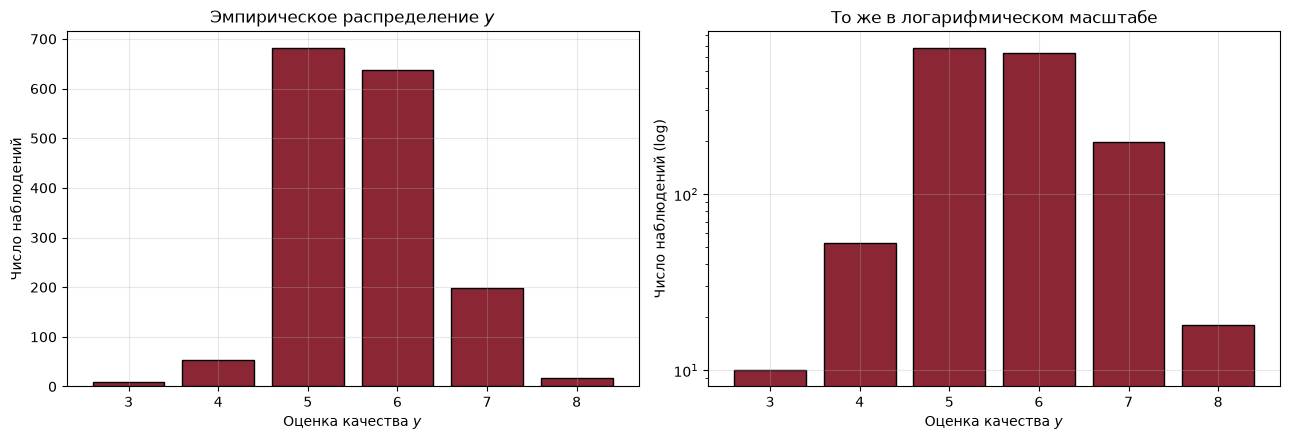

Среднее:      5.636
Медиана:      6.0
Ст. отклонение: 0.808


In [23]:
counts = df["quality"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(counts.index, counts.values, color="#8B2635", edgecolor="black")
axes[0].set_xlabel("Оценка качества $y$")
axes[0].set_ylabel("Число наблюдений")
axes[0].set_title("Эмпирическое распределение $y$")

axes[1].bar(counts.index, counts.values, color="#8B2635", edgecolor="black")
axes[1].set_yscale("log")
axes[1].set_xlabel("Оценка качества $y$")
axes[1].set_ylabel("Число наблюдений (log)")
axes[1].set_title("То же в логарифмическом масштабе")

plt.tight_layout()
plt.show()

print(f"Среднее:      {df['quality'].mean():.3f}")
print(f"Медиана:      {df['quality'].median():.1f}")
print(f"Ст. отклонение: {df['quality'].std():.3f}")

Логарифмическая шкала на правом графике делает видимыми малочисленные классы,
которые на линейной шкале почти неразличимы.

### 5.2 Распределения признаков

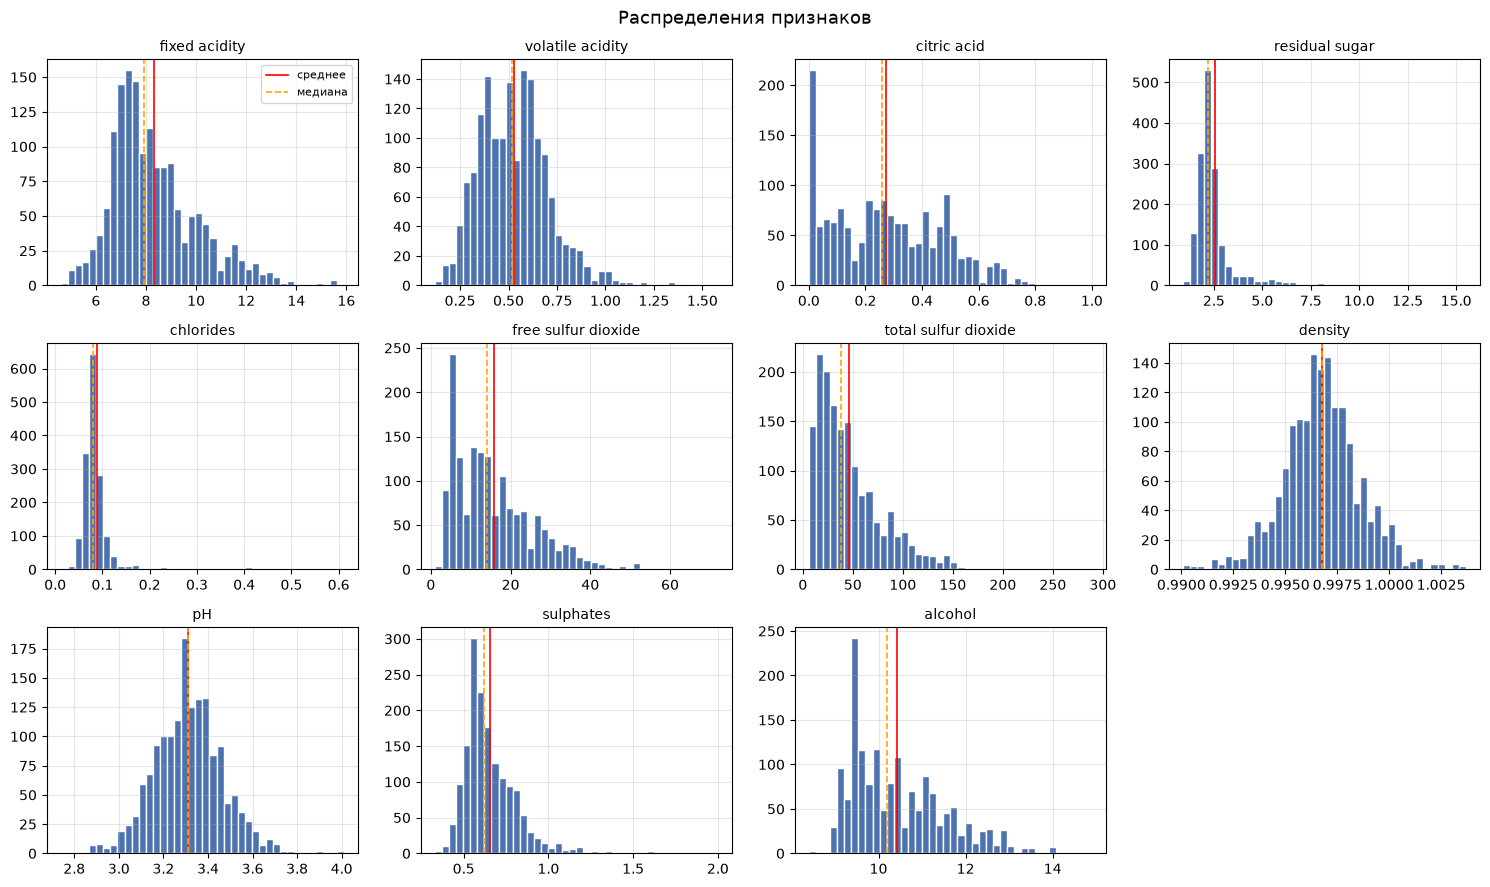

In [24]:
features = [c for c in df.columns if c not in ("quality", "alcohol_q")]

fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.flat, features):
    ax.hist(df[col], bins=40, color="#4C72B0", edgecolor="white")
    ax.axvline(df[col].mean(), color="red", linestyle="-", lw=1.2, label="среднее")
    ax.axvline(df[col].median(), color="orange", linestyle="--", lw=1.2, label="медиана")
    ax.set_title(col, fontsize=10)
axes.flat[-1].axis("off")
axes.flat[0].legend(fontsize=8)
plt.suptitle("Распределения признаков", fontsize=13)
plt.tight_layout()
plt.show()

Расхождение среднего и медианы служит индикатором асимметрии распределения.
Формально её измеряет выборочный коэффициент асимметрии.

Для симметричного распределения коэффициент = 0; положительные значения означают правый хвост.

In [25]:
skew = df[features].skew().sort_values(ascending=False)
skew.to_frame("коэффициент асимметрии")

,коэффициент асимметрии
chlorides,5.680
residual sugar,4.541
sulphates,2.429
total sulfur dioxide,1.516
free sulfur dioxide,1.251
fixed acidity,0.983
alcohol,0.861
volatile acidity,0.672
citric acid,0.318
pH,0.194


### 5.3 Масштабы признаков

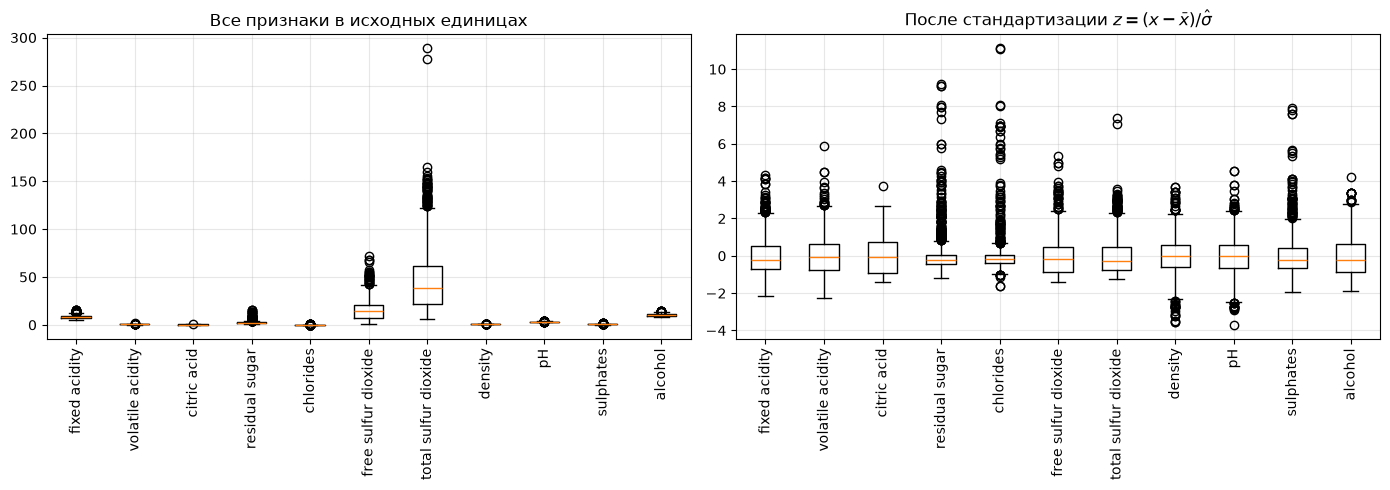

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot([df[c] for c in features], tick_labels=features)
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_title("Все признаки в исходных единицах")

z = (df[features] - df[features].mean()) / df[features].std()
axes[1].boxplot([z[c] for c in features], tick_labels=features)
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_title("После стандартизации $z = (x - \\bar{x}) / \\hat{\\sigma}$")

plt.tight_layout()
plt.show()

Левый график непригоден для анализа: признак `total sulfur dioxide` с диапазоном $[6; 289]$
визуально подавляет `density` с диапазоном $[0.990; 1.004]$ (и не только).

После стандартизации все признаки приведены к нулевому среднему и единичной дисперсии,
что делает их сопоставимыми. Точки за пределами усов — наблюдения, отстоящие от квартилей
более чем на $1.5 \cdot \text{IQR}$.

Называть их выбросами в смысле «ошибка данных» здесь нельзя. Правило $1.5 \cdot \text{IQR}$
настроено на симметричное распределение: у скошенного признака длинный правый хвост сам
по себе выводит часть наблюдений за усы, даже если все значения абсолютно корректны.
Как мы видели в 3.2, скошенность у концентраций — норма.

### 5.4 Условные распределения признаков

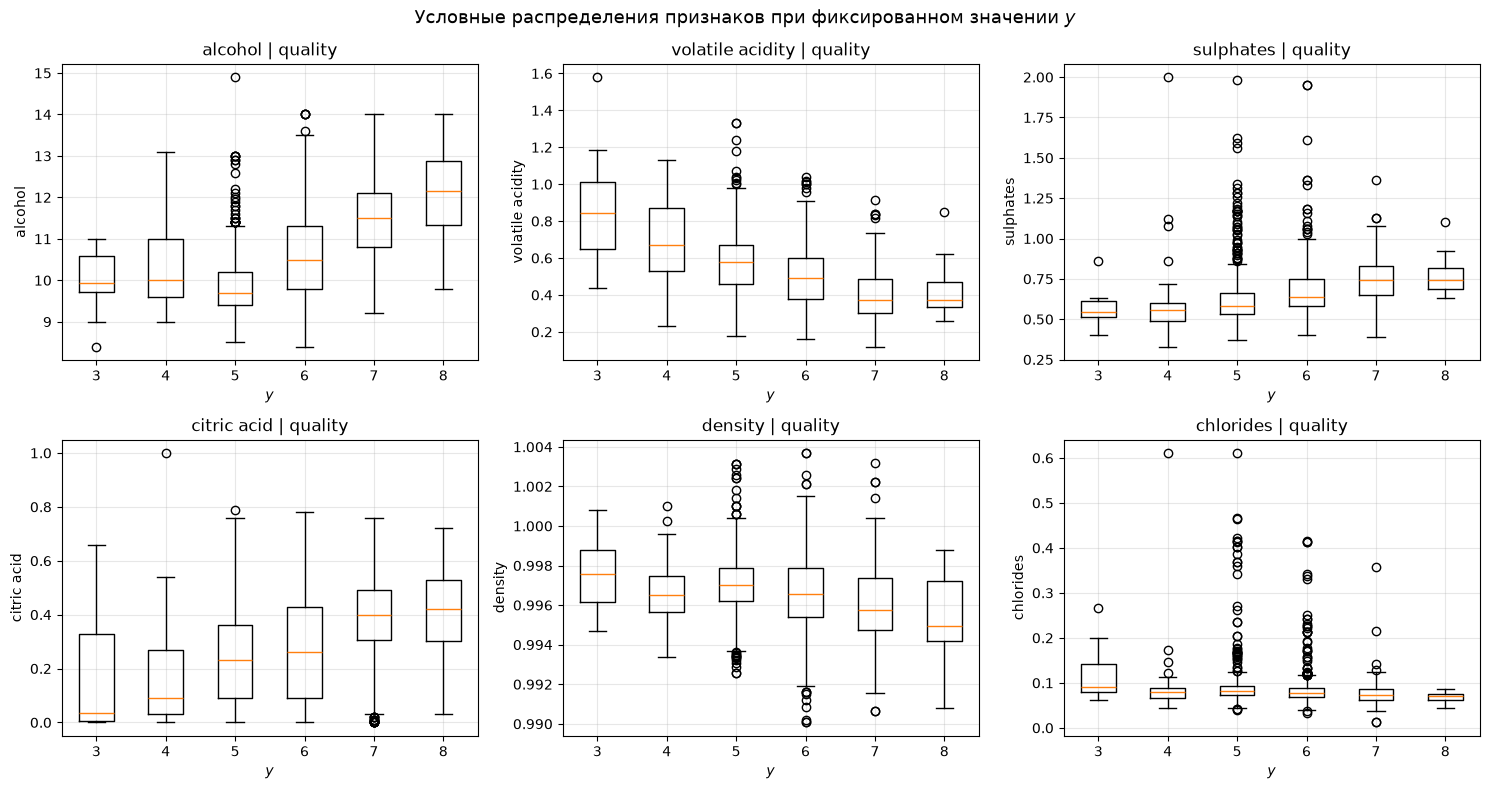

In [27]:
show = ["alcohol", "volatile acidity", "sulphates", "citric acid", "density", "chlorides"]
levels = sorted(df["quality"].unique())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, show):
    ax.boxplot([df.loc[df["quality"] == q, col] for q in levels], tick_labels=levels)
    ax.set_xlabel("$y$")
    ax.set_ylabel(col)
    ax.set_title(f"{col} | quality")

plt.suptitle("Условные распределения признаков при фиксированном значении $y$", fontsize=13)
plt.tight_layout()
plt.show()

Графики отображают условные распределения $x_j \mid y = k$. Наиболее выраженная
монотонная зависимость медианы от $y$ наблюдается у `alcohol` (возрастающая)
и `volatile acidity` (убывающая).

### 5.5 Корреляционный анализ

**Коэффициент корреляции** измеряет линейную составляющую связи (представлена выборочная):

$$r_{xy} = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2}\,\sqrt{\sum_{i=1}^n (y_i - \bar{y})^2}} \in [-1, 1].$$

Слово «линейную» в определении существенно: $r$ показывает, насколько точно точки ложатся
на прямую. Для сильной, но непрямой зависимости $r$ может оказаться небольшим,
поэтому близкое к нулю значение означает отсутствие линейной связи, но никак не полное отсутствие связи.

In [28]:
pearson = df[features + ["quality"]].corr(method="pearson")["quality"].drop("quality")
pearson.sort_values().to_frame("корреляция с quality")

,корреляция с quality
volatile acidity,-0.391
total sulfur dioxide,-0.185
density,-0.175
chlorides,-0.129
pH,-0.058
free sulfur dioxide,-0.051
residual sugar,0.014
fixed acidity,0.124
citric acid,0.226
sulphates,0.251


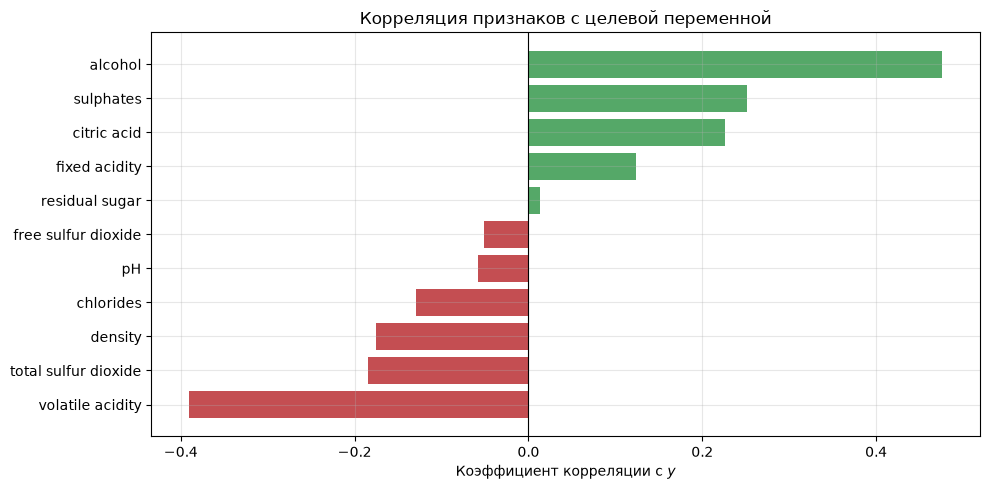

In [29]:
order = pearson.sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(order.index, order.values,
        color=["#C44E52" if v < 0 else "#55A868" for v in order])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Коэффициент корреляции с $y$")
ax.set_title("Корреляция признаков с целевой переменной")
plt.tight_layout()
plt.show()

Выделяются `alcohol` (0.48) и `volatile acidity` (−0.39) — те же два признака, что и на
боксплотах в 5.4. У остальных связь с оценкой слабее 0.26 по модулю, а у `residual sugar`
корреляция 0.014, то есть содержание сахара на оценку красного вина линейно не влияет.

Высокая корреляция с $y$ не означает, что признак влияет на оценку. Крепость растёт
вместе с оценкой, но дегустатор оценивает не спирт: высокое содержание алкоголя получается
из зрелого винограда с высоким содержанием сахара, и зрелость сырья сказывается и на
крепости, и на вкусе. Крепость здесь скорее сопутствует качеству, а не является его причиной, — долив
спирта в готовое вино, оценку не поднять. Для предсказания этого достаточно, а для выводов
о том, что менять в производстве, уже нет.

### 5.6 Матрица корреляций признаков

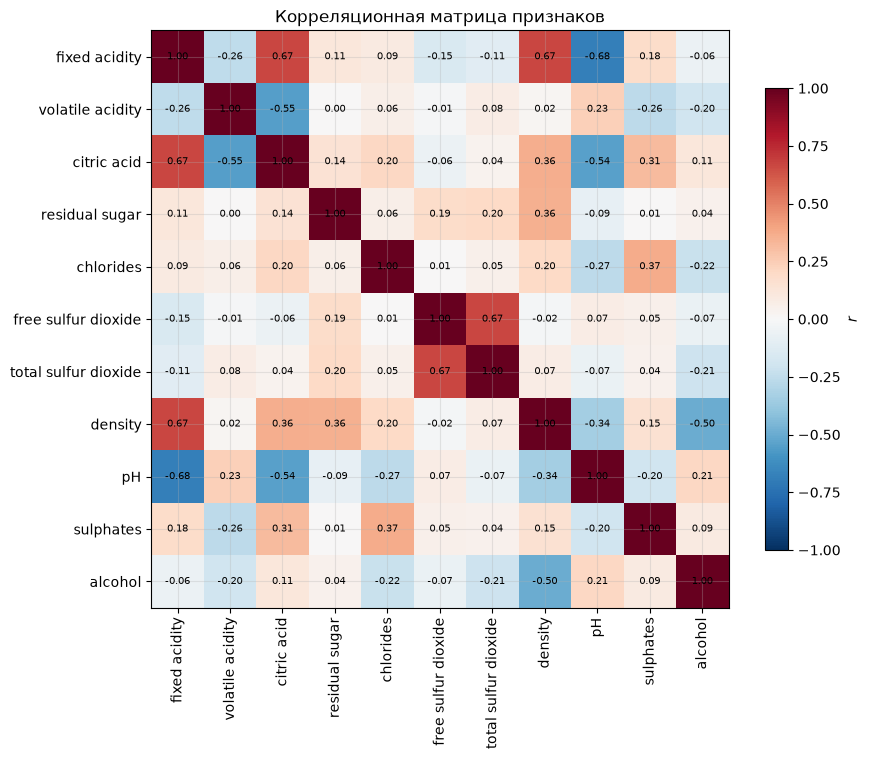

In [30]:
corr = df[features].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, shrink=0.8, label="$r$")
ax.set_title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

Пары признаков с наибольшей по модулю корреляцией

In [31]:
pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .sort_values(key=abs, ascending=False)
        .head(6)
)
pairs.to_frame("r")

r
fixed acidity       pH                   -0.683
                    citric acid           0.672
                    density               0.668
free sulfur dioxide total sulfur dioxide  0.668
volatile acidity    citric acid          -0.552
citric acid         pH                   -0.542

Признаки существенно коррелированы между собой: $|r| > 0.6$ для четырёх пар (существенно относительно значений, полученных на текущем датасете).

Это явление называется **мультиколлинеарностью** - связь признаков между собой.

Вопрос «какой вклад вносит каждый признак» становится плохо поставленным, потому что признаки
меняются не независимо. Помимо прочего, данное явление может ломать модели с математической точки зрения.

## 6. Разбиение выборки и константная модель

### 6.1 Обучающая и тестовая выборки

Как отмечено в разделе 1.2, минимизируется эмпирический риск $\hat{R}(f)$,
а содержательный интерес представляет теоретический риск $R(f)$.
Оценка $\hat{R}(f)$, вычисленная на тех же данных, на которых подбиралась $f$,
является **смещённой**: модель настраивалась в том числе на случайные особенности
конкретной выборки.

Поэтому выборка разбивается на непересекающиеся части:

$$X = X_{\text{train}} \sqcup X_{\text{test}}, \qquad
X_{\text{train}} \cap X_{\text{test}} = \varnothing.$$

Модель подбирается по $X_{\text{train}}$, а оценка риска вычисляется по $X_{\text{test}}$,
которая в подборе не участвовала и потому даёт несмещённую оценку $R(f)$.

In [32]:
from sklearn.model_selection import train_test_split

X = df[features]
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, 
)

print(f"n_train = {len(X_train)},  n_test = {len(X_test)},  p = {X.shape[1]}")
print(f"Среднее y на train: {y_train.mean():.4f}")
print(f"Среднее y на test:  {y_test.mean():.4f}")

n_train = 1279,  n_test = 320,  p = 11
Среднее y на train: 5.6239
Среднее y на test:  5.6844


### 6.2 Метрики качества регрессии

Пусть $\hat{y}_i = f(\mathbf{x}_i)$ — предсказания на тестовой выборке объёма $n$.

**Средняя абсолютная ошибка:**
$$\mathrm{MAE} = \frac{1}{m}\sum_{i=1}^{n} \lvert y_i - \hat{y}_i \rvert.$$

**Корень из среднеквадратичной ошибки:**
$$\mathrm{RMSE} = \sqrt{\frac{1}{m}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}.$$

Обе метрики измеряются в единицах целевой переменной. Поскольку RMSE использует квадрат
отклонения, она придаёт большим ошибкам больший вес.

Разница между ними — в том, что считать более серьёзной ошибкой. Для MAE две ошибки
по одному баллу и одна ошибка на два балла равноценны. Для RMSE вторая вдвое хуже:
$2^2 = 4$ против $1^2 + 1^2 = 2$.

**Коэффициент детерминации:**
$$R^2 = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}.$$

В отличие от первых двух, $R^2$ безразмерен: это отношение ошибки модели к ошибке
предсказания средним. $R^2 = 1$ соответствует точному предсказанию; $R^2 = 0$ — качеству
предсказания средним значением; $R^2 < 0$ означает, что модель уступает константе $\bar{y}$.
Отрицательные значения ничему не противоречат: $R^2$ не является квадратом какой-либо
величины, это только обозначение.

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

scores = {}

def evaluate(name, y_true, y_pred, store=True):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2 = r2_score(y_true, y_pred)
    if store:
        scores[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    print(f"{name:<34} MAE = {mae:.4f}   RMSE = {rmse:.4f}   R2 = {r2:+.4f}")
    return mae

### 6.3 Константная модель как нижняя граница

Рассмотрим класс $\mathcal{F}_0 = \{f(\mathbf{x}) \equiv c,\; c \in \mathbb{R}\}$ —
модели, которые никак не учитывают признаки. Оптимальная константа зависит от функции потерь.

**Квадратичные потери.** Минимизируем $\;S(c) = \sum_{i=1}^n (y_i - c)^2$.
Из условия первого порядка:
$$\frac{dS}{dc} = -2\sum_{i=1}^n (y_i - c) = 0 \;\Longrightarrow\; c^{*} = \frac{1}{n}\sum_{i=1}^n y_i = \bar{y},$$
причём $S''(c) = 2n > 0$, то есть найден минимум.

**Абсолютные потери.** Для $\;A(c) = \sum_{i=1}^n \lvert y_i - c \rvert$ производная
(в точках $c \ne y_i$) равна разности числа наблюдений слева и справа от $c$;
она обращается в нуль, когда по обе стороны находится равное число наблюдений:
$$c^{*} = \mathrm{median}(y_1, \dots, y_n).$$

Таким образом, **среднее минимизирует RMSE, медиана минимизирует MAE**.

In [34]:
const_mean = np.full(len(y_test), y_train.mean())
const_median = np.full(len(y_test), y_train.median())

print(f"Среднее по train:  {y_train.mean():.4f}")
print(f"Медиана по train:  {y_train.median():.1f}\n")

evaluate("Константа = среднее", y_test, const_mean)
evaluate("Константа = медиана", y_test, const_median)

Среднее по train:  5.6239
Медиана по train:  6.0

Константа = среднее                MAE = 0.6853   RMSE = 0.8107   R2 = -0.0056
Константа = медиана                MAE = 0.6406   RMSE = 0.8678   R2 = -0.1524


0.640625

Результат согласуется с теоретическими ожиданиями:

* по MAE лучше медиана: $0.6406 < 0.6853$;
* по RMSE лучше среднее: $0.8107 < 0.8678$.

Заодно видно, как сильно метрика меняет картину. У медианной константы $R^2 = -0.15$:
$R^2$ построен на квадратах ошибок, поэтому модель, оптимальную для MAE, он считает
хуже бесполезной. Одна и та же модель выглядит лучшей или худшей в зависимости от того,
чем её мерить, — значит, метрику нужно фиксировать (договариваться о ней) до начала моделирования, исходя
из содержания задачи, а не выбирать потом по результату.

Далее в качестве опорной величины возьмем $\mathrm{MAE}_{\text{baseline}} = 0.6406$. Модель, не превосходящая это значение,
не извлекает из признаков никакой полезной информации.

In [35]:
baseline_mae = mean_absolute_error(y_test, const_median)
print(f"Опорное значение MAE: {baseline_mae:.4f}")

Опорное значение MAE: 0.6406


## 7. Линейная регрессия

### 7.1 Модель

Класс линейных функций:

$$f(\mathbf{x}) = w_0 + \sum_{j=1}^{p} w_j x_j = \mathbf{w}^{\top}\tilde{\mathbf{x}},
\qquad \tilde{\mathbf{x}} = (1, x_1, \dots, x_p)^{\top}.$$

Параметры $\mathbf{w} = (w_0, w_1, \dots, w_p)^{\top}$ подбираются **методом наименьших квадратов**:

$$\mathbf{w}^{*} = \arg\min_{\mathbf{w}} \; \lVert X\mathbf{w} - \mathbf{y} \rVert_2^2
= \arg\min_{\mathbf{w}} \sum_{i=1}^{n}\big(y_i - \mathbf{w}^{\top}\tilde{\mathbf{x}}_i\big)^2,$$

где $X \in \mathbb{R}^{n \times (p+1)}$ — матрица объектов-признаков.

Дифференцируя по $\mathbf{w}$ и приравнивая градиент нулю, получаем следующее решение

$$X^{\top}X\,\mathbf{w} = X^{\top}\mathbf{y} \;\Longrightarrow\; \mathbf{w}^{*} = (X^{\top}X)^{-1}X^{\top}\mathbf{y},$$

при условии невырожденности $X^{\top}X$. Эта задача имеет аналитическое решение,
то есть итеративная оптимизация не требуется. Но что нас может ограничивать в повсеместном применении этого решения?

In [36]:
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)
lin_pred = lin.predict(X_test)

evaluate("Константа = медиана", y_test, const_median, store=False)
lin_mae = evaluate("Линейная регрессия", y_test, lin_pred)

print(f"\nСнижение MAE относительно константы: {(1 - lin_mae / baseline_mae):.1%}")

Константа = медиана                MAE = 0.6406   RMSE = 0.8678   R2 = -0.1524
Линейная регрессия                 MAE = 0.5035   RMSE = 0.6245   R2 = +0.4032

Снижение MAE относительно константы: 21.4%


MAE снизился с 0.64 до 0.50, то есть признаки действительно несут информацию об оценке.
При этом типичная ошибка составляет полбалла при шаге шкалы в один балл — модель
определяет уровень вина, но не различает соседние оценки.

Проверим совпадение решения `scikit-learn` с явным решением нормального уравнения:

In [37]:
X_mat = np.column_stack([np.ones(len(X_train)), X_train.values])
w_analytic = np.linalg.solve(X_mat.T @ X_mat, X_mat.T @ y_train.values)

w_sklearn = np.concatenate([[lin.intercept_], lin.coef_])

print("Максимальное расхождение коэффициентов:", np.abs(w_analytic - w_sklearn).max())

Максимальное расхождение коэффициентов: 4.545636933528385e-08


In [38]:
print(f"Диапазон предсказаний модели: [{lin_pred.min():.2f}, {lin_pred.max():.2f}]")
print(f"Диапазон реальных оценок:     [{y_test.min()}, {y_test.max()}]")

Диапазон предсказаний модели: [4.71, 6.80]
Диапазон реальных оценок:     [3, 8]


Предсказания укладываются в отрезок $[4.71,\, 6.80]$, тогда как оценки принимают
значения от 3 до 8. Модель не выдаёт крайних значений вовсе.

Это свойство квадратичных потерь. Минимизируя средний квадрат ошибки,
модель оценивает условное среднее $\mathbb{E}[y \mid \mathbf{x}]$, а среднее по группе
никогда не выходит за пределы группы и лежит тем ближе к центру, чем менее однородна
группа. Предсказать 8 означало бы утверждать, что при таком составе почти все вина
получают 8 — а в данных даже среди самых крепких вин оценки разные.

## 8. Мультиколлинеарность и интерпретация коэффициентов

### 8.1 Проблема несопоставимых масштабов

Коэффициент $w_j$ имеет размерность $y/x_j$, поэтому величины $w_j$
для признаков в разных единицах несопоставимы.

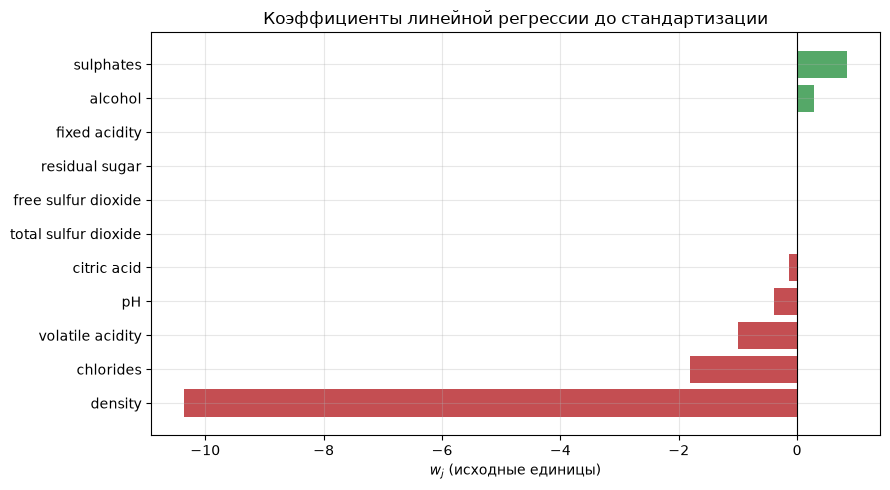

,w_j
density,-10.352
chlorides,-1.807
volatile acidity,-1.001
pH,-0.394
citric acid,-0.141
total sulfur dioxide,-0.004
free sulfur dioxide,0.006
residual sugar,0.007
fixed acidity,0.023
alcohol,0.282


In [39]:
coefs_raw = pd.Series(lin.coef_, index=features).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(coefs_raw.index, coefs_raw.values,
        color=["#C44E52" if v < 0 else "#55A868" for v in coefs_raw])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("$w_j$ (исходные единицы)")
ax.set_title("Коэффициенты линейной регрессии до стандартизации")
plt.tight_layout()
plt.show()

coefs_raw.to_frame("w_j")

Наибольший по модулю коэффициент — у `density` ($w \approx -10.4$), наименьший —
у `total sulfur dioxide` ($w \approx -0.004$). Разница в три с лишним порядка
объясняется не важностью признаков, а их единицами: `density` меняется в пределах
0.014, а `total sulfur dioxide` — в пределах 283. Чтобы вклад в предсказание был
сопоставим, коэффициент при `density` обязан быть во столько же раз больше.

Помогает избавиться от этой проблемы **стандартизация**, она приводит признаки к сопоставимому виду:
$$z_{ij} = \frac{x_{ij} - \bar{x}_j}{\hat{\sigma}_j}.$$

После неё коэффициент $w_j$ интерпретируется как изменение $\hat{y}$
при изменении $x_j$ на единицу измерения при фиксированных прочих признаках.
Проблема масштаба больше не мешает.

Параметры преобразования ($\bar{x}_j, \hat{\sigma}_j$) должны оцениваться только по
обучающей выборке, иначе информация о тестовой выборке проникает в процедуру обучения.
Конструкция `Pipeline` обеспечивает это автоматически: при вызове `fit` она применяет
`fit` к `StandardScaler` только на переданных данных, а при `predict` использует уже
сохранённые средние и дисперсии.

In [40]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lin_scaled = make_pipeline(StandardScaler(), LinearRegression())
lin_scaled.fit(X_train, y_train)

evaluate("Линейная регрессия", y_test, lin_pred, store=False)
evaluate("Линейная + стандартизация", y_test, lin_scaled.predict(X_test), store=False)

Линейная регрессия                 MAE = 0.5035   RMSE = 0.6245   R2 = +0.4032
Линейная + стандартизация          MAE = 0.5035   RMSE = 0.6245   R2 = +0.4032


0.5035304415524375

Метрики совпадают с точностью до вычислительной погрешности.
Стандартизация — аффинное преобразование признаков, а класс линейных функций
относительно таких преобразований замкнут: изменяются значения коэффициентов, но не сама модель.

Проще говоря, модель может скомпенсировать любое растяжение признака обратным изменением
коэффициента, и предсказания останутся теми же. Стандартизация нужна не для точности,
а для сопоставимости коэффициентов (а для методов, где решение ищется итеративно (градиентные методы), —
ещё и для скорости сходимости).

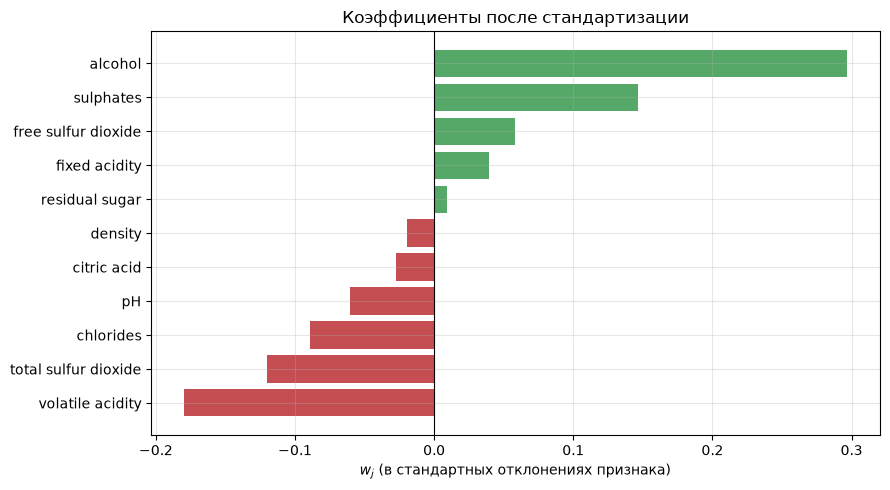

,w_j станд.,корреляция с y
volatile acidity,-0.179,-0.391
total sulfur dioxide,-0.120,-0.185
chlorides,-0.089,-0.129
pH,-0.061,-0.058
citric acid,-0.028,0.226
density,-0.019,-0.175
residual sugar,0.009,0.014
fixed acidity,0.040,0.124
free sulfur dioxide,0.058,-0.051
sulphates,0.147,0.251


In [41]:
coefs_std = pd.Series(
    lin_scaled.named_steps["linearregression"].coef_, index=features
).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(coefs_std.index, coefs_std.values,
        color=["#C44E52" if v < 0 else "#55A868" for v in coefs_std])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("$w_j$ (в стандартных отклонениях признака)")
ax.set_title("Коэффициенты после стандартизации")
plt.tight_layout()
plt.show()

pd.DataFrame({"w_j станд.": coefs_std, "корреляция с y": pearson[coefs_std.index]})

Теперь на первых местах `alcohol` (0.30) и `volatile acidity` (−0.18) — те же признаки,
что и в разделе 5.5. А вот `density`, у которого нестандартизованный коэффициент был
наибольшим по модулю, получает вес −0.02, близкий к нулю: его большое значение
действительно было целиком эффектом масштаба.

Сравните два столбца из таблицы выше. У большинства признаков знак коэффициента совпадает
со знаком корреляции, но у `citric acid` корреляция положительна (0.23), а коэффициент
отрицателен (−0.03). Признак, который сам по себе связан с оценкой положительно,
в модели работает в минус. Почему так может происходить?

### 8.2 Откуда берётся разворот знака

Посмотрим, что происходит с коэффициентом `citric acid` по мере добавления в модель
коррелированных с ним признаков.

In [42]:
for cols in (["citric acid"],
             ["citric acid", "fixed acidity"],
             ["citric acid", "fixed acidity", "volatile acidity"]):
    m = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train[cols], y_train)
    w = m.named_steps["linearregression"].coef_[0]
    print(f"w(citric acid) = {w:+.3f}   в модели из признаков: {', '.join(cols)}")

print()
print(f"corr(citric acid, fixed acidity)    = {df['citric acid'].corr(df['fixed acidity']):+.2f}")
print(f"corr(citric acid, volatile acidity) = {df['citric acid'].corr(df['volatile acidity']):+.2f}")

w(citric acid) = +0.174   в модели из признаков: citric acid
w(citric acid) = +0.196   в модели из признаков: citric acid, fixed acidity
w(citric acid) = -0.016   в модели из признаков: citric acid, fixed acidity, volatile acidity

corr(citric acid, fixed acidity)    = +0.67
corr(citric acid, volatile acidity) = -0.55


В одиночку `citric acid` получает коэффициент +0.17, согласный с его корреляцией.
Добавление `fixed acidity` почти ничего не меняет. А вот после добавления
`volatile acidity` коэффициент падает до −0.02.

Объяснение в корреляции −0.55 между `citric acid` и `volatile acidity`. Вина с высоким
содержанием лимонной кислоты — это, как правило, вина с низкой летучей кислотностью,
а низкая летучая кислотность сама по себе сильно связана с хорошей оценкой. Пока
`volatile acidity` в модели нет, `citric acid` работает её заместителем и получает
её положительный эффект. Как только настоящая причина появляется в модели явно,
заимствованный эффект уходит, и остаётся собственный вклад признака — близкий к нулю.

Отсюда и смысл оговорки «при фиксированных прочих признаках» в интерпретации
коэффициента: она предполагает, что признак можно менять, не меняя остальные.
Для `citric acid` это неверно.

### 8.3 Фактор инфляции дисперсии

Для признака $x_j$ построим регрессию на **все остальные признаки** и обозначим её коэффициент
детерминации $R_j^2$. **Фактор инфляции дисперсии** определяется как

$$\mathrm{VIF}_j = \frac{1}{1 - R_j^2}.$$

Величина $\mathrm{VIF}_j$ показывает, во сколько раз дисперсия оценки $\hat{w}_j$ больше
той, что была бы при некоррелированных признаках. Значения $\mathrm{VIF} > 5$
принято считать признаком существенной мультиколлинеарности,
$\mathrm{VIF} > 10$ — сильной.

Смысл формулы: $R_j^2$ — это доля признака, которую можно восстановить по остальным.
Чем она ближе к единице, тем меньше в признаке собственной, не дублирующейся информации,
и тем меньше данных остаётся на оценку его коэффициента. При $R_j^2 = 0.9$ в знаменателе
остаётся 0.1, и дисперсия оценки вырастает в десять раз.

In [43]:
Z = (X - X.mean()) / X.std()

vif = {}
for col in features:
    others = Z.drop(columns=col)
    r2_j = LinearRegression().fit(others, Z[col]).score(others, Z[col])
    vif[col] = 1 / (1 - r2_j)

pd.Series(vif).sort_values(ascending=False).to_frame("VIF")

,VIF
fixed acidity,7.768
density,6.344
pH,3.330
citric acid,3.128
alcohol,3.031
total sulfur dioxide,2.187
free sulfur dioxide,1.963
volatile acidity,1.789
residual sugar,1.703
chlorides,1.482


Наибольшие значения — у `fixed acidity` (7.77) и `density` (6.34): эти признаки на 87% и 84%
восстанавливаются по остальным.

## 9. Переобучение, регуляризация и утечка данных

### 9.1 Расширение класса моделей

Линейность модели относится к параметрам, а не к исходным признакам.
Добавив полиномиальные признаки степени $d$ — все произведения вида
$x_1^{a_1} x_2^{a_2}\cdots x_p^{a_p}$ с $\sum_j a_j \le d$ — мы остаёмся в классе
линейных по параметрам моделей, но существенно расширяем множество описываемых зависимостей.

Это даёт модели то, чего ей не хватало раньше: квадраты позволяют описать
неравномерные шаги, а произведения $x_i x_j$ — взаимодействия
признаков, которых мы не нашли в 4.5, но которые могут быть и у других пар.

Число признаков растёт комбинаторно:

$$p_d = \binom{p + d}{d} - 1.$$

При $p = 11$: $p_1 = 11$, $p_2 = 77$, $p_3 = 363$.
Последнее значение сопоставимо с объёмом обучающей выборки $n_{\text{train}} = 1279$.

In [44]:
from math import comb
from sklearn.preprocessing import PolynomialFeatures

for d in (1, 2, 3, 4):
    print(f"d = {d}:  p_d = C({11 + d}, {d}) - 1 = {comb(11 + d, d) - 1}")

d = 1:  p_d = C(12, 1) - 1 = 11
d = 2:  p_d = C(13, 2) - 1 = 77
d = 3:  p_d = C(14, 3) - 1 = 363
d = 4:  p_d = C(15, 4) - 1 = 1364


In [45]:
rows = []
for d in (1, 2, 3, 4):
    model = make_pipeline(
        PolynomialFeatures(degree=d, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    )
    model.fit(X_train, y_train)
    n_feat = model.named_steps["polynomialfeatures"].n_output_features_
    rows.append({
        "степень d": d,
        "p_d": n_feat,
        "MAE train": mean_absolute_error(y_train, model.predict(X_train)),
        "MAE test": mean_absolute_error(y_test, model.predict(X_test)),
        "R2 test": r2_score(y_test, model.predict(X_test)),
    })

poly_results = pd.DataFrame(rows).set_index("степень d")
poly_results

,p_d,MAE train,MAE test,R2 test
степень d,,,,
1,11,0.500,0.504,0.403
2,77,0.472,0.495,0.416
3,363,0.373,0.592,-0.168
4,1364,0.157,4.234,-611.272


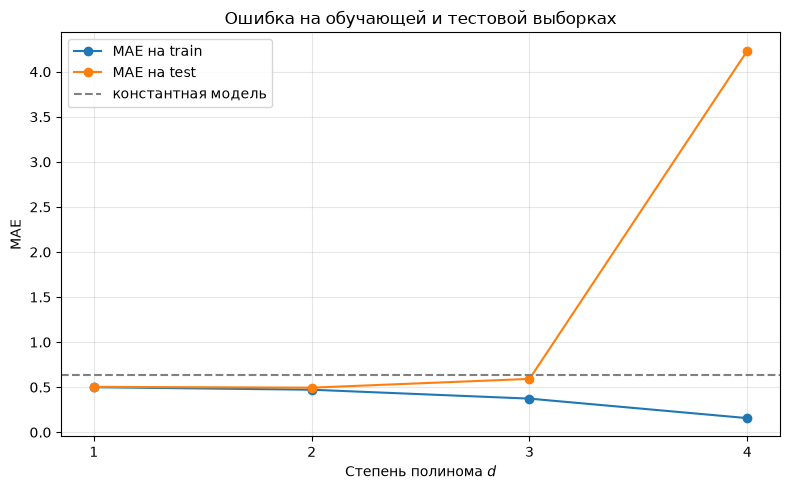

In [46]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(poly_results.index, poly_results["MAE train"], "o-", label="MAE на train")
ax.plot(poly_results.index, poly_results["MAE test"], "o-", label="MAE на test")
ax.axhline(baseline_mae, color="gray", linestyle="--", label="константная модель")
ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel("Степень полинома $d$")
ax.set_ylabel("MAE")
ax.set_title("Ошибка на обучающей и тестовой выборках")
ax.legend()
plt.tight_layout()
plt.show()

### 9.2 Переобучение

Ошибка на обучающей выборке падает монотонно: 0.500 → 0.472 → 0.363. Ошибка на тестовой
сначала немного улучшается (0.504 → 0.495), а затем портится до 0.568, и $R^2 = -0.004$
означает, что модель уступает константе.

Это **переобучение**: модель с $p_3 = 363$ параметрами при $n_{\text{train}} = 1279$
наблюдениях воспроизводит случайные особенности обучающей выборки,
не соответствующие закономерностям распределения $p(\mathbf{x}, y)$. Для $p_4$ эта картина еще более выражена.

Расходящиеся кривые на графике — характерная картина. Параметров почти столько же,
сколько наблюдений, и модели хватает свободы, чтобы пройти близко к каждой точке
обучающей выборки, включая её шумовую составляющую. Шум в следующей выборке будет другим,
поэтому подогнанные под него коэффициенты на тесте только вредят.

Полезно смотреть именно на зазор между кривыми, а не на одну из них. Малая обучающая
ошибка при большом зазоре означает запоминание; обе ошибки большие — модель слишком
проста (недообучение). Здесь $d=2$ даёт лучший компромисс из трёх вариантов.

### 9.3 Регуляризация

**Гребневая регрессия** (Ridge) добавляет к функционалу штраф за норму вектора коэффициентов:

$$\mathbf{w}^{*} = \arg\min_{\mathbf{w}} \Big\{ \lVert X\mathbf{w} - \mathbf{y}\rVert_2^2
+ \alpha \lVert \mathbf{w} \rVert_2^2 \Big\}, \qquad \alpha \ge 0.$$

Решение существует и единственно при любом $\alpha > 0$:

$$\mathbf{w}^{*} = (X^{\top}X + \alpha I)^{-1}X^{\top}\mathbf{y}.$$

Добавление $\alpha I$ улучшает обусловленность матрицы, что устраняет неустойчивость обращения матрицы.

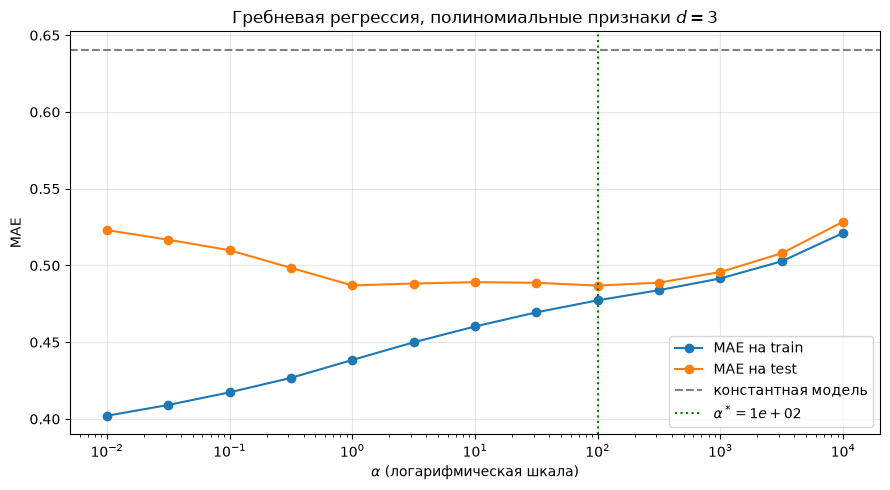

alpha* = 100
MAE train = 0.4773, MAE test = 0.4869


In [47]:
from sklearn.linear_model import Ridge

alphas = np.logspace(-2, 4, 13)
train_err, test_err = [], []

for a in alphas:
    model = make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        Ridge(alpha=a),
    )
    model.fit(X_train, y_train)
    train_err.append(mean_absolute_error(y_train, model.predict(X_train)))
    test_err.append(mean_absolute_error(y_test, model.predict(X_test)))

fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogx(alphas, train_err, "o-", label="MAE на train")
ax.semilogx(alphas, test_err, "o-", label="MAE на test")
ax.axhline(baseline_mae, color="gray", linestyle="--", label="константная модель")
best_i = int(np.argmin(test_err))
ax.axvline(alphas[best_i], color="green", linestyle=":", label=f"$\\alpha^* = {alphas[best_i]:.2g}$")
ax.set_xlabel("$\\alpha$ (логарифмическая шкала)")
ax.set_ylabel("MAE")
ax.set_title("Гребневая регрессия, полиномиальные признаки $d = 3$")
ax.legend()
plt.tight_layout()
plt.show()

print(f"alpha* = {alphas[best_i]:.4g}")
print(f"MAE train = {train_err[best_i]:.4f}, MAE test = {test_err[best_i]:.4f}")

In [48]:
ridge_best = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    Ridge(alpha=alphas[best_i]),
).fit(X_train, y_train)

evaluate("Константа = медиана", y_test, const_median, store=False)
evaluate("Линейная регрессия", y_test, lin_pred, store=False)
evaluate("Полином d=3 без регуляризации", y_test,
         make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(),
                       LinearRegression()).fit(X_train, y_train).predict(X_test))
evaluate("Полином d=3 + Ridge", y_test, ridge_best.predict(X_test))

Константа = медиана                MAE = 0.6406   RMSE = 0.8678   R2 = -0.1524
Линейная регрессия                 MAE = 0.5035   RMSE = 0.6245   R2 = +0.4032
Полином d=3 без регуляризации      MAE = 0.5919   RMSE = 0.8736   R2 = -0.1677
Полином d=3 + Ridge                MAE = 0.4869   RMSE = 0.6072   R2 = +0.4358


0.4868916160825387

Тестовый MAE снижается с 0.568 до 0.487 — лучше и константы, и линейной регрессии
без полиномиальных признаков (0.504).

Обратите внимание на форму кривых: обучающая ошибка с ростом $\alpha$ монотонно
ухудшается, а тестовая сначала улучшается и только потом портится. Регуляризация
сознательно ухудшает подгонку к обучающим данным, и это оказывается выгодно.
При слишком большом $\alpha$ штраф пересиливает данные, коэффициенты стягиваются к нулю,
и модель вырождается в константу.

### 9.4 Утечка данных

Вернёмся к 240 дубликатам, обнаруженным в разделе 3.2. Разбиение на train и test
выполнялось **после** того, как дубликаты уже присутствовали в таблице.
Следовательно, часть тестовых наблюдений имеет точную копию в обучающей выборке.

In [49]:
twins = X_test.merge(X_train.drop_duplicates(), how="inner")
print(f"Тестовых наблюдений с точной копией в train: {len(twins)} из {len(X_test)} "
      f"({len(twins) / len(X_test):.1%})")

Тестовых наблюдений с точной копией в train: 64 из 320 (20.0%)


Пятая часть тестовой выборки не удовлетворяет условию
$X_{\text{train}} \cap X_{\text{test}} = \varnothing$ по признакам.
Это **утечка данных**: оценка риска $\hat{R}(f)$ на такой тестовой выборке смещена вниз.

Устраним дубликаты **до** разбиения и сравним обе модели.

In [50]:
df_clean = df.drop_duplicates(subset=features + ["quality"])
print(f"Наблюдений: {len(df)} → {len(df_clean)} (удалено {len(df) - len(df_clean)})")

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    df_clean[features], df_clean["quality"], test_size=0.2, random_state=RANDOM_STATE
)

def fit_pair(Xtr, ytr, Xte, yte):
    lr = LinearRegression().fit(Xtr, ytr)
    p3 = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(),
                       LinearRegression()).fit(Xtr, ytr)
    return (mean_absolute_error(yte, lr.predict(Xte)),
            mean_absolute_error(yte, p3.predict(Xte)))

with_dup = fit_pair(X_train, y_train, X_test, y_test)
without_dup = fit_pair(Xc_train, yc_train, Xc_test, yc_test)

leakage = pd.DataFrame(
    {"с дубликатами": with_dup, "без дубликатов": without_dup},
    index=["Линейная регрессия (MAE)", "Полином d=3 (MAE)"],
)
leakage["занижение MAE"] = leakage["без дубликатов"] - leakage["с дубликатами"]
leakage.round(3)

Наблюдений: 1599 → 1359 (удалено 240)


,с дубликатами,без дубликатов,занижение MAE
Линейная регрессия (MAE),0.504,0.504,0.001
Полином d=3 (MAE),0.592,0.691,0.099


Столбец «занижение MAE» показывает, насколько дубликаты улучшили оценку ошибки.
Для двух моделей результат разный:

* у линейной регрессии занижения практически нет: 0.001 из-за округлений;
* у полинома степени 3 MAE занижен на 0.12: 0.568 вместо честных 0.688.

Разница объясняется сложностью модели. Утекший объект помогает только той модели,
которая способна его запомнить. Линейная регрессия с 11 параметрами описывает выборку
единой плоскостью и не может подстроиться под отдельное наблюдение, поэтому его копия
в тесте не даёт ей преимущества. Полином с 363 параметрами запоминать умеет —
и получает прибавку в качестве.

## 10. Итоги

In [51]:
summary = pd.DataFrame(scores).T
summary.style.format("{:.4f}").highlight_min(subset=["MAE", "RMSE"], color="green")

,MAE,RMSE,R2
Константа = среднее,0.6853,0.8107,-0.0056
Константа = медиана,0.6406,0.8678,-0.1524
Линейная регрессия,0.5035,0.6245,0.4032
Полином d=3 без регуляризации,0.5919,0.8736,-0.1677
Полином d=3 + Ridge,0.4869,0.6072,0.4358


Что стоит запомнить:

- **Внимательное предобрабатываем данные.** Проверки на пропущенные значения, дубликаты, типы данных и тд.

- **Качество измеряется на данных, которых модель не видела.** Разбиение на трейн и тест обязательно.

- **Нужна опорная модель (baseline).** MAE 0.49 — хороший результат только рядом с 0.64 у оптимальной
константы. Без этого числа многие метрика не интерпретируются.

- **Метрика выбирается до моделирования.**

- **Сложность модели подбирается, а не максимизируется.** Расширение класса функций
снижает обучающую ошибку всегда, а тестовую — только до некоторого предела.

- **Борьба с мультиколлинеарностью.** Важно даже в нелинейных моделях, так как может ломаться интерпретация.
